# Exploration : français (Allociné) et fongbé (corpus parallèle)

Volumes, longueurs, audit du corpus à étiquettes automatiques, et aperçu de la projection lexicale.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROC = ROOT / "data" / "processed"
RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
REP = ROOT / "reports"

fr_train = pd.read_csv(PROC / "fr_train.csv")
fr_test = pd.read_csv(PROC / "fr_test.csv")
fon_tr = pd.read_csv(PROC / "fon_proj_train.csv")
fon_te = pd.read_csv(PROC / "fon_proj_test.csv")
verif = pd.read_csv(PROC / "fon_verifie.csv")
audit = json.loads((RAW / "audit_fon_sentiments.json").read_text())
print("français train/test", len(fr_train), len(fr_test))
print("fongbé projeté train/test", len(fon_tr), len(fon_te))
print("fongbé vérifié", len(verif), verif.label.value_counts().to_dict())


français train/test 10000 2000
fongbé projeté train/test 701 220
fongbé vérifié 68 {1: 36, 0: 32}


## Audit du corpus « Fon Sentiment » (écarté)

In [2]:
print("n =", audit["n"])
part = 100 * audit["part_avec_lettre_fon"]
print("avec lettre fon ɔɛɖ :", audit["avec_lettre_fon_ɔɛɖ"], f"({part:.1f} %)")
print("latin sans lettre fon :", audit["latin_sans_lettre_fon"])
print("allure française sans lettre fon :", audit["allure_francaise_sans_lettre_fon"])
print("décision :", audit["decision"])


n = 34915
avec lettre fon ɔɛɖ : 14649 (42.0 %)
latin sans lettre fon : 16791
allure française sans lettre fon : 4559
décision : écarté de l'entraînement et de l'évaluation : étiquettes non humaines et mélange de langues visible


## Longueur des textes

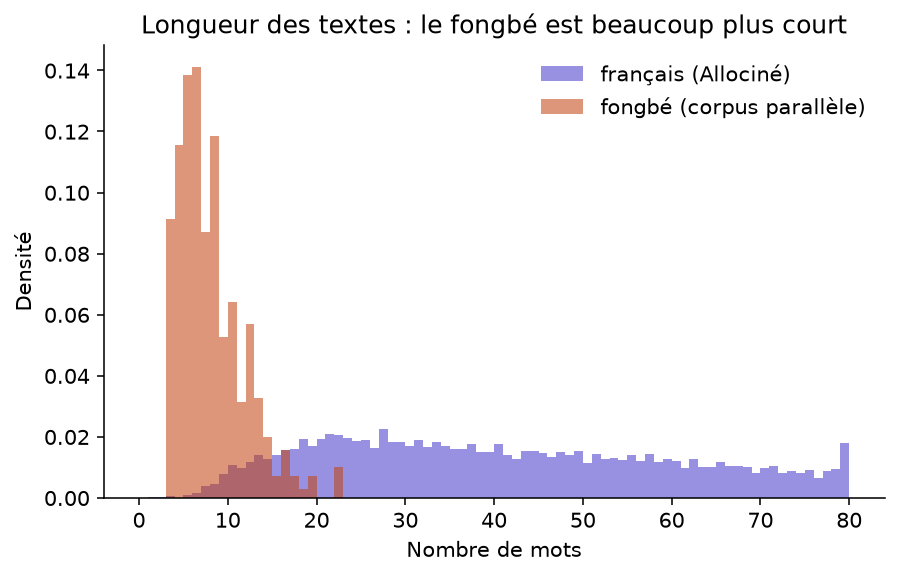

médiane mots FR (train) 47.0
médiane mots FON (train projeté) 7.0


In [3]:
display(Image(str(FIG / "02_longueurs.png")))
print("médiane mots FR (train)", fr_train.texte.str.split().str.len().median())
print("médiane mots FON (train projeté)", fon_tr.texte.str.split().str.len().median())


## Composition des jeux d'évaluation

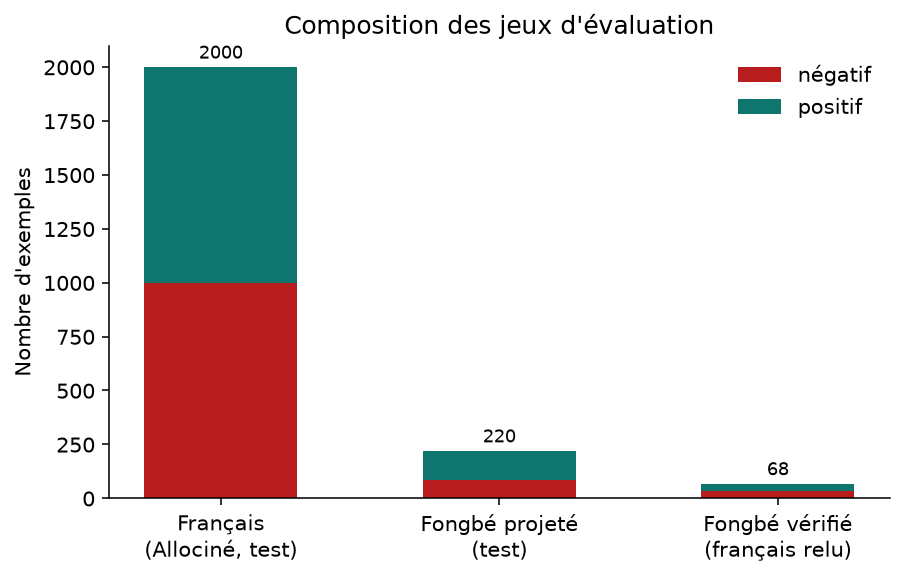

In [4]:
display(Image(str(FIG / "01_volumes.png")))

## Exemples du jeu fongbé relu (polarité contrôlée sur le français)

In [5]:
for lab, nom in ((1, "positif"), (0, "négatif")):
    print("---", nom, "---")
    sub = verif[verif.label == lab].head(3)
    for _, r in sub.iterrows():
        print("FR :", r.texte_fr)
        print("FON:", r.texte)
        print()


--- positif ---
FR : la radio du bénin a donné un beau conte hier soir
FON: xóɖɔ́núwɛ̀kɛtɛ̀n benɛ to tɔ́n ɔ́ ɖɔ̀ hwenuxó víví ɖokpó sɔ̀ zăn mɛ̀

FR : et je te remercie encore
FON: bɔ̀ un ka sɔ́ lɛ́ dó kú nú we mɔ̆

FR : c'est heureux pour moi
FON: afɔ nyɔ́ nú mì

--- négatif ---
FR : causer de la douleur à quelqu'un
FON: wà nŭ xá mɛ

FR : c'est tout à fait impossible désolée
FON: nu ma jɔ wɛ mi sɔ kɛ mi

FR : j'ai peur de la mort
FON: un ɖì kú xɛsì

